In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import os,cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
from keras.utils import np_utils

In [3]:
data_path='/content/drive/MyDrive/RASHI/DATA/Maize Leaf Disease Dataset' # Give your path here.
data_dir_list = ['0', '1', '2', '3']
img_data_list=[]
labels = []

for dataset in data_dir_list:
    img_list=os.listdir(data_path+'/'+ dataset)
    print ('Loaded the images of dataset-'+'{}\n'.format(dataset))
    for img in img_list:
        input_img=cv2.imread(data_path + '/'+ dataset + '/'+ img )
        # input_img=cv2.IMREAD_GRAYSCALE
        labels.append(dataset)
        input_img_resize=cv2.resize(input_img,(128, 128))  # Here, Write your image size.
        img_data_list.append(input_img_resize)

label=np.array(labels)
data = np.array(img_data_list)
# print(data)
data = data.astype('float32')
data = data/255
data.shape

Loaded the images of dataset-0

Loaded the images of dataset-1

Loaded the images of dataset-2

Loaded the images of dataset-3



(4208, 128, 128, 3)

In [4]:
num_classes = 4 # Number of classes in your dataset
Y = np_utils.to_categorical(label, num_classes)
x,y = shuffle(data,Y, random_state=2)
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size = 0.1, random_state = 2)
print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

Shape of X_train: (3787, 128, 128, 3)
Shape of X_test: (421, 128, 128, 3)
Shape of y_train: (3787, 4)
Shape of y_test: (421, 4)


In [5]:
X_train = X_train.reshape(-1,128,128, 3)
X_test = X_test.reshape(-1, 128, 128, 3)

In [6]:
from keras.layers import Conv2D, GlobalAveragePooling2D, Reshape, Dense, Multiply, Add

def eca_module(input_tensor, gamma=2, b=1):
    channels = input_tensor.shape[-1]
    print(channels)

    squeeze = GlobalAveragePooling2D()(input_tensor)
    excitation = Dense(units=channels // gamma)(squeeze)
    excitation = Activation('relu')(excitation)
    excitation = Dense(units=channels)(excitation)
    excitation = Activation('sigmoid')(excitation)
    excitation = Reshape((1, 1, channels))(excitation)

    scale = Multiply()([input_tensor, excitation])

    output = Add()([scale, input_tensor])
    return output

In [7]:
def residual_csa_module(input_tensor, reduction_ratio=16):
    channels = input_tensor.shape[-1]

    # Convolutional layer for feature extraction
    conv1 = Conv2D(filters=channels // reduction_ratio, kernel_size=(1, 1), padding='same', activation='relu')(input_tensor)
    conv2 = Conv2D(filters=channels // reduction_ratio, kernel_size=(1, 1), padding='same', activation='relu')(conv1)
    conv3 = Conv2D(filters=channels, kernel_size=(1, 1), padding='same', activation='relu')(conv2)

    # Spatial attention mechanism
    attention_map = Conv2D(filters=1, kernel_size=(1, 1), padding='same', activation='sigmoid')(conv3)

    # Multiply attention map with input tensor
    attention = Multiply()([attention_map, input_tensor])

    # Residual connection
    output = Add()([attention, input_tensor])

    return output

In [8]:
from keras.layers import Conv2D, SeparableConv2D, Concatenate, AveragePooling2D

def inception_block(input_tensor, filters):
    # Path 1: 1x1 Convolution
    path1 = Conv2D(filters[0], kernel_size=(1, 1), padding='same', activation='relu')(input_tensor)

    # Path 2: 1x1 Convolution followed by 3x3 Depthwise Separable Convolution
    path2 = Conv2D(filters[1], kernel_size=(1, 1), padding='same', activation='relu')(input_tensor)
    path2 = SeparableConv2D(filters[2], kernel_size=(3, 3), padding='same', activation='relu')(path2)

    # Path 3: 1x1 Convolution followed by two 3x3 Depthwise Separable Convolutions
    path3 = Conv2D(filters[3], kernel_size=(1, 1), padding='same', activation='relu')(input_tensor)
    path3 = SeparableConv2D(filters[4], kernel_size=(3, 3), padding='same', activation='relu')(path3)
    path3 = SeparableConv2D(filters[5], kernel_size=(3, 3), padding='same', activation='relu')(path3)

    # Path 4: 3x3 Average Pooling followed by 1x1 Convolution
    path4 = AveragePooling2D(pool_size=(3, 3), strides=(1, 1), padding='same')(input_tensor)
    path4 = Conv2D(filters[6], kernel_size=(1, 1), padding='same', activation='relu')(path4)

    # Concatenate the paths
    output_tensor = Concatenate(axis=-1)([path1, path2, path3, path4])

    return output_tensor

In [9]:
import keras
from keras.applications import EfficientNetB0, ResNet50, VGG16, InceptionV3
from keras.layers import Dense, GlobalAveragePooling2D, Conv2D, Flatten, Add, Activation, Input, MaxPooling2D
from tensorflow.keras.optimizers import RMSprop, Adam, SGD
from tensorflow.keras import regularizers
from keras.models import Model

# base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(128, 128, 3))
# for layer in base_model.layers:
#     layer.trainable = False

# x = base_model.output
input = Input((128, 128, 3))
x = Conv2D(filters=64, kernel_size=(3, 3), activation='relu')(input)
inception_block1 = inception_block(x, filters=[16, 32, 64, 32, 64, 128, 32])
x1 = Conv2D(filters=64, kernel_size=(3, 3), padding = 'same', activation='relu')(inception_block1)
x = Add()([x, x1])
x = Conv2D(filters=128, kernel_size=(3, 3), activation='relu')(x)
x = MaxPooling2D()(x)

# inception_block1 = inception_block(x, filters=[16, 32, 64, 32, 64, 128, 32])
# x = Conv2D(filters=256, kernel_size=(3, 3), activation='relu')(inception_block1)
# x = Conv2D(filters=128, kernel_size=(3, 3), activation='relu')(x)
# x = MaxPooling2D()(x)

eca_module1 = eca_module(x)
res_csa_module1 = residual_csa_module(x)

x = Add()([x, eca_module1, res_csa_module1])
x = Conv2D(filters=256, kernel_size=(3, 3), activation='relu')(x)

x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dense(128, activation='relu')(x)
# Add a fully connected layer for classification
output = Dense(4, activation='softmax')(x)

# Create the model
model = Model(inputs=input, outputs=output)

# Compile the model
# optimizer = Adam(learning_rate=0.0001, weight_decay = 0.99)
# sgd = SGD(learning_rate=0.001, momentum=0.9)
model.compile(optimizer= 'adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Print the model summary
model.summary()

128
Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 128, 128, 3  0           []                               
                                )]                                                                
                                                                                                  
 conv2d (Conv2D)                (None, 126, 126, 64  1792        ['input_1[0][0]']                
                                )                                                                 
                                                                                                  
 conv2d_3 (Conv2D)              (None, 126, 126, 32  2080        ['conv2d[0][0]']                 
                                )                                                         

In [10]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
early_stopping = EarlyStopping(
                              patience=20,
                              min_delta=0.001,
                              monitor="val_loss",
                              restore_best_weights=True
                              )
# Define the model checkpoint callback to save the best weights
checkpoint = ModelCheckpoint('/content/drive/MyDrive/RASHI/maze_best_Plant_weights.h5', monitor='val_loss', save_best_only=True)

history = model.fit( X_train, y_train, batch_size = 16, epochs = 100,
                    validation_data = (X_test , y_test), callbacks=[early_stopping, checkpoint], verbose =1)

Epoch 1/100
237/237 [==============================] - 54s 165ms/step - loss: 0.6839 - accuracy: 0.7074 - val_loss: 0.3727 - val_accuracy: 0.8409
Epoch 2/100
237/237 [==============================] - 34s 143ms/step - loss: 0.4622 - accuracy: 0.8123 - val_loss: 0.4092 - val_accuracy: 0.8385
Epoch 3/100
237/237 [==============================] - 34s 142ms/step - loss: 0.3990 - accuracy: 0.8262 - val_loss: 0.3739 - val_accuracy: 0.8409
Epoch 4/100
237/237 [==============================] - 34s 144ms/step - loss: 0.3913 - accuracy: 0.8255 - val_loss: 0.3721 - val_accuracy: 0.8551
Epoch 5/100
237/237 [==============================] - 34s 145ms/step - loss: 0.3996 - accuracy: 0.8292 - val_loss: 0.3549 - val_accuracy: 0.8527
Epoch 6/100
237/237 [==============================] - 34s 145ms/step - loss: 0.3506 - accuracy: 0.8463 - val_loss: 0.3189 - val_accuracy: 0.8504
Epoch 7/100
237/237 [==============================] - 34s 142ms/step - loss: 0.3718 - accuracy: 0.8431 - val_loss: 0.3252 -

<Figure size 640x480 with 0 Axes>

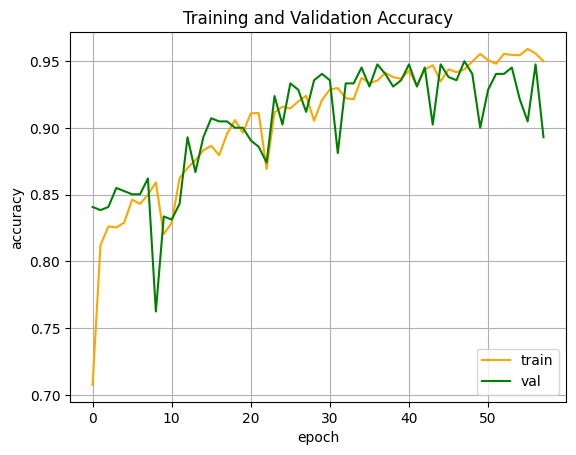

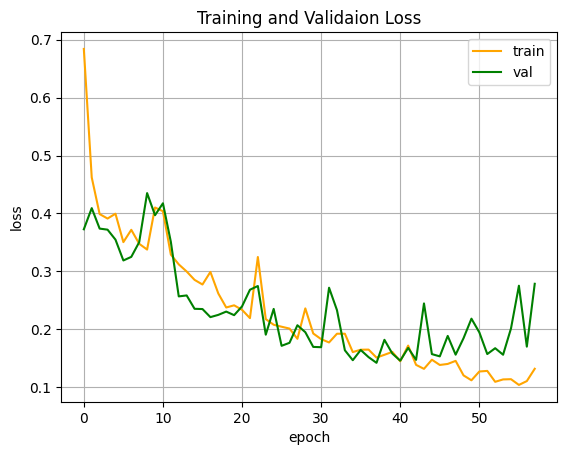

<Figure size 640x480 with 0 Axes>

In [11]:
import matplotlib.image as mpimg
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(acc))

plt.plot(epochs, acc, 'orange')
plt.plot(epochs, val_acc, 'g')
plt.title('Training and Validation Accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='lower right')
plt.grid()
plt.figure()

plt.plot(epochs, loss, 'orange')
plt.plot(epochs, val_loss, 'g')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper right')
plt.title('Training and Validaion Loss')
plt.grid()
plt.figure()

In [12]:
# Predicting the Test set results
pred = model.predict(X_test)
print("Y_pred:", pred)
print("*****************")
y_pred = np.argmax(pred, axis = 1)
print("Y_pred:", y_pred)
print("*****************")
print("Y_test:", y_test)
y_true = np.argmax(y_test, axis = 1)
print("*****************")
print("Y_test:", y_true)

14/14 [==============================] - 4s 75ms/step
Y_pred: [[1.3766457e-09 1.2966345e-10 1.9415176e-10 1.0000000e+00]
 [8.1158835e-01 1.3932052e-01 4.9090911e-02 1.9838984e-07]
 [9.9382996e-06 1.6807764e-05 2.6817217e-05 9.9994648e-01]
 ...
 [9.9900395e-01 2.3184798e-06 9.9302339e-04 8.2732845e-07]
 [8.2960892e-01 9.1377117e-02 7.9013802e-02 1.6121581e-07]
 [9.9510044e-01 1.7934931e-04 4.7028554e-03 1.7304756e-05]]
*****************
Y_pred: [3 0 3 3 0 1 1 3 0 1 2 2 1 2 3 3 1 1 3 3 1 3 1 2 1 1 0 3 3 3 3 3 3 0 1 3 3
 3 0 0 1 1 0 0 0 1 3 3 1 2 0 3 3 0 1 2 0 0 0 0 1 3 0 0 1 1 0 3 3 0 0 1 1 0
 3 0 1 2 0 0 3 0 3 2 2 0 3 0 1 3 0 3 0 2 2 2 2 0 0 1 2 3 0 3 1 1 0 2 0 1 3
 2 0 1 2 1 2 1 0 1 1 1 3 1 1 3 0 0 3 1 0 3 1 1 0 3 0 1 1 1 3 1 0 3 3 1 3 3
 3 0 3 3 1 3 3 3 0 0 0 0 0 0 2 0 0 3 0 2 1 3 1 0 3 0 2 0 0 1 3 1 3 2 0 2 0
 3 0 3 0 1 0 1 3 1 0 3 3 1 0 0 1 3 1 3 3 1 3 1 1 1 3 1 1 0 0 1 0 3 1 2 0 3
 3 2 2 1 0 3 0 1 2 3 1 0 3 1 3 3 1 3 3 0 3 0 3 0 0 3 3 0 1 3 2 0 3 1 2 3 3
 3 1 1 1 0 2 0 3 1 3 3 3 1 

In [13]:
#Making the Confusion Matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true, y_pred)
target_names = ['blight', 'common_rust', 'gray_leaf_spot', 'healthy']

Text(0.5, 23.38159722222222, 'Predicted label')

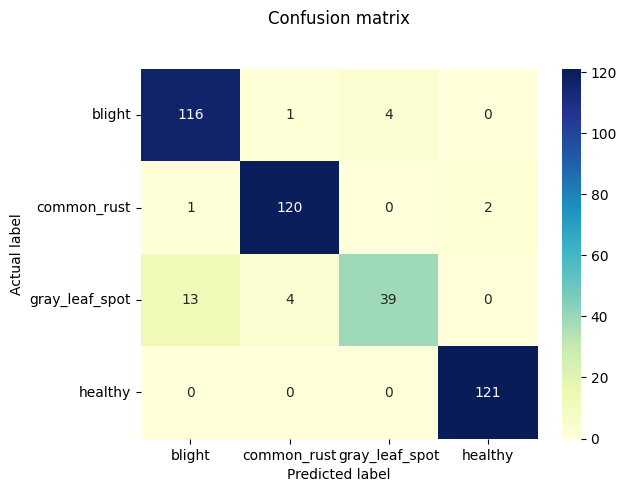

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
p = sns.heatmap(pd.DataFrame(cm), annot=True,xticklabels=target_names, yticklabels=target_names, cmap="YlGnBu" ,fmt='g')
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')

In [15]:
#import classification_report
from sklearn.metrics import classification_report
print(classification_report(y_true,y_pred, target_names = target_names))

                precision    recall  f1-score   support

        blight       0.89      0.96      0.92       121
   common_rust       0.96      0.98      0.97       123
gray_leaf_spot       0.91      0.70      0.79        56
       healthy       0.98      1.00      0.99       121

      accuracy                           0.94       421
     macro avg       0.94      0.91      0.92       421
  weighted avg       0.94      0.94      0.94       421



In [16]:
from sklearn.metrics import roc_curve, auc
from itertools import cycle

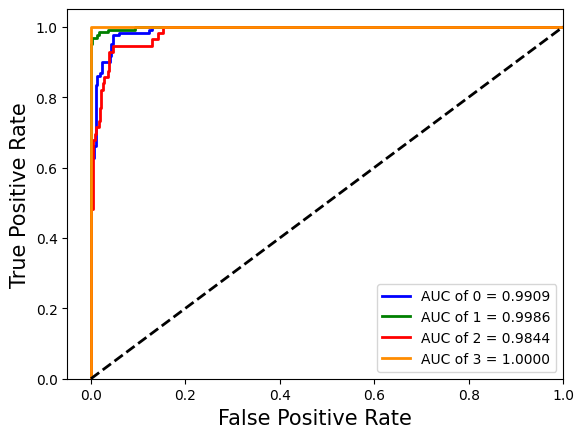

In [17]:
fpr = dict()
tpr = dict()
roc_auc = dict()
lw=2
for i in range(4):
    fpr[i], tpr[i], _ = roc_curve(y_test[:, i], pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
colors =cycle(['blue', 'green', 'red','darkorange'])
for i, color in zip(range(4), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label='AUC of {0} = {1:0.4f}'
             ''.format(i, roc_auc[i]))
plt.plot([0, 1], [0, 1], 'k--', lw=lw)
plt.xlim([-0.05, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate',fontsize=15)
plt.ylabel('True Positive Rate',fontsize=15)
# plt.title('Receiver operating characteristic for multi-class data')
plt.legend(loc="lower right")
plt.show()